In [6]:
# ==========================================
# Import Module
# ==========================================

import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

np.random.seed(42) 
print("All ready!")

All ready!


In [7]:
# ==========================================
# Determine the model
# ==========================================

import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split

# 1. Load the Iris dataset
iris = datasets.load_iris()
X = iris.data    # Shape: (150, 4)
y = iris.target  # Shape: (150,)

# 2. Split the data into training (80%) and testing (20%) sets
# random_state ensures reproducibility across different runs
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Standardize features (Zero mean, unit variance)
# IMPORTANT: Calculate mean and standard deviation using ONLY the training set
# to prevent data leakage into the test set.
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# 4. One-Hot Encoding for the target variable
# This is crucial for computing the cross-entropy loss with softmax outputs.
def to_one_hot(y, num_classes=3):
    """
    Converts a 1D array of integer labels into a 2D One-Hot encoded matrix.
    """
    one_hot = np.zeros((y.size, num_classes))
    one_hot[np.arange(y.size), y] = 1
    return one_hot

y_train_encoded = to_one_hot(y_train)
y_test_encoded = to_one_hot(y_test)

print(f"X_train shape: {X_train.shape}")
print(f"y_train_encoded shape: {y_train_encoded.shape}")

X_train shape: (120, 4)
y_train_encoded shape: (120, 3)


In [8]:
# ==========================================
# Activation Functions Module
# ==========================================

def relu(Z):
    """
    Rectified Linear Unit (ReLU) activation function.
    
    Parameters:
    Z (numpy.ndarray): The linear transformation output matrix.
    
    Returns:
    numpy.ndarray: The activated matrix where negative values are set to 0.
    """
    return np.maximum(0, Z)

def softmax(Z):
    """
    Softmax activation function with numerical stability optimization.
    
    Parameters:
    Z (numpy.ndarray): The output layer predictions, shape [batch_size, num_classes].
    
    Returns:
    numpy.ndarray: The probability distribution matrix for each sample.
    """
    # Find the maximum value in each row (sample) for numerical stability.
    # keepdims=True ensures the shape allows for proper broadcasting during subtraction.
    Z_max = np.max(Z, axis=1, keepdims=True)
    
    # Subtract the maximum value to prevent exponential overflow, then compute exponentials.
    exp_Z = np.exp(Z - Z_max)
    
    # Normalize by dividing by the sum of exponentials for each row.
    probabilities = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)
    
    return probabilities

print("Activation functions module loaded successfully.")

Activation functions module loaded successfully.


In [16]:
# ==========================================
# MLP Core Class
# ==========================================

class SimpleMLP:
    def __init__(self, input_size=4, hidden_size=16, output_size=3, learning_rate=0.01):
        self.lr = learning_rate
        
        # np.sqrt(2.0 / input_size) 
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden_size))
        
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
        self.b2 = np.zeros((1, output_size))

    def forward(self, X):
        """
        Perform forward propagation.
        
        Parameters:
        X (numpy.ndarray): Input data matrix of shape [batch_size, input_size].
        
        Returns:
        tuple: (A2, cache)
               A2 is the final probability output.
               cache is a dictionary containing intermediate values for backpropagation.
        """
        # Layer 1: Hidden Layer
        Z1 = np.dot(X, self.W1) + self.b1
        A1 = relu(Z1)  # Using the global relu function defined in Cell 3
        
        # Layer 2: Output Layer
        Z2 = np.dot(A1, self.W2) + self.b2
        A2 = softmax(Z2) # Using the global softmax function defined in Cell 3
        
        # Store intermediate values for backpropagation (Crucial for HD!)
        cache = {
            "Z1": Z1,
            "A1": A1,
            "Z2": Z2,
            "A2": A2
        }
        
        return A2, cache

    def compute_loss(self, Y_true, Y_pred):
        """
        Compute the categorical Cross-Entropy Loss.
        
        Parameters:
        Y_true (numpy.ndarray): One-hot encoded true labels, shape [batch_size, num_classes].
        Y_pred (numpy.ndarray): Predicted probabilities (A2), shape [batch_size, num_classes].
        
        Returns:
        float: The average cross-entropy loss over the batch.
        """
        m = Y_true.shape[0] # Number of samples in the batch
        
        # Add a tiny epsilon to Y_pred to prevent log(0) which causes NaN
        epsilon = 1e-8
        
        # Cross-Entropy Formula: - (1/m) * sum(Y_true * log(Y_pred))
        # We use element-wise multiplication (*) and then sum all elements.
        loss = - (1.0 / m) * np.sum(Y_true * np.log(Y_pred + epsilon))
        
        return loss

    def backward(self, X, Y_true, cache):
        """
        Perform backward propagation to calculate gradients and update weights using SGD.
        
        Parameters:
        X (numpy.ndarray): Input data matrix for the current batch.
        Y_true (numpy.ndarray): True one-hot encoded labels for the current batch.
        cache (dict): Dictionary containing intermediate values from forward propagation.
        """
        m = X.shape[0]  # Number of samples in the current mini-batch
        
        # Retrieve intermediate values
        Z1 = cache["Z1"]
        A1 = cache["A1"]
        A2 = cache["A2"]
        
        # ---------------------------------------------------------
        # Step 1: Output Layer Gradients (Layer 2)
        # ---------------------------------------------------------
        # Derivative of Cross-Entropy Loss with Softmax simplifies to (Prediction - True)
        dZ2 = A2 - Y_true
        
        # Gradients for W2 and b2
        # dW2 shape: [hidden_size, num_classes] -> (16, 120) * (120, 3) = (16, 3)
        dW2 = (1.0 / m) * np.dot(A1.T, dZ2)
        # db2 shape: [1, num_classes] -> sum along the batch axis
        db2 = (1.0 / m) * np.sum(dZ2, axis=0, keepdims=True)
        
        # ---------------------------------------------------------
        # Step 2: Hidden Layer Gradients (Layer 1)
        # ---------------------------------------------------------
        # Propagate the error back to the hidden layer
        # dA1 shape: [batch_size, hidden_size] -> (120, 3) * (3, 16) = (120, 16)
        dA1 = np.dot(dZ2, self.W2.T)
        
        # Derivative of ReLU: 1 if Z1 > 0, else 0
        dZ1 = dA1 * (Z1 > 0)
        
        # Gradients for W1 and b1
        # dW1 shape: [input_size, hidden_size] -> (4, 120) * (120, 16) = (4, 16)
        dW1 = (1.0 / m) * np.dot(X.T, dZ1)
        # db1 shape: [1, hidden_size]
        db1 = (1.0 / m) * np.sum(dZ1, axis=0, keepdims=True)
        
        # ---------------------------------------------------------
        # Step 3: Parameter Updates (Stochastic Gradient Descent)
        # ---------------------------------------------------------
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2

    def train(self, X_train, Y_train, epochs=100, batch_size=16):
        """
        Train the MLP using Mini-Batch Stochastic Gradient Descent.
        """
        num_samples = X_train.shape[0]
        history = {'loss': [], 'accuracy': []}
        
        for epoch in range(epochs):
            # Shuffle the dataset at the beginning of each epoch to prevent cycles
            permutation = np.random.permutation(num_samples)
            X_train_shuffled = X_train[permutation]
            Y_train_shuffled = Y_train[permutation]
            
            epoch_losses = []
            
            # Iterate over mini-batches
            for i in range(0, num_samples, batch_size):
                # Extract the current batch
                X_batch = X_train_shuffled[i:i + batch_size]
                Y_batch = Y_train_shuffled[i:i + batch_size]
                
                # Forward pass
                A2, cache = self.forward(X_batch)
                
                # Compute loss
                batch_loss = self.compute_loss(Y_batch, A2)
                epoch_losses.append(batch_loss)
                
                # Backward pass and parameter update
                self.backward(X_batch, Y_batch, cache)
            
            # Calculate and record metrics for the current epoch
            avg_epoch_loss = np.mean(epoch_losses)
            history['loss'].append(avg_epoch_loss)
            
            # Calculate training accuracy
            predictions = self.predict(X_train)
            true_labels = np.argmax(Y_train, axis=1)
            accuracy = np.mean(predictions == true_labels)
            history['accuracy'].append(accuracy)
            
            # Print progress every 10 epochs
            if (epoch + 1) % 10 == 0 or epoch == 0:
                print(f"Epoch {epoch + 1:3d}/{epochs} - Loss: {avg_epoch_loss:.4f}, Accuracy: {accuracy:.4f}")
                
        return history

    def predict(self, X):
        """
        Predict the class labels for the input data.
        """
        A2, _ = self.forward(X)
        # Return the index of the class with the highest probability
        return np.argmax(A2, axis=1)

print("SimpleMLP has been defined")

#trainning
test_mlp = SimpleMLP()
sample_X = X_train[:5]
sample_Y = y_train_encoded[:5]

test_predictions, test_cache = test_mlp.forward(sample_X)
test_loss = test_mlp.compute_loss(sample_Y, test_predictions)

print(f"test shape: {sample_X.shape}")
print(f"prediction shape: {test_predictions.shape}") 
print(f"loss: {test_loss:.4f}") 

SimpleMLP has been defined
test shape: (5, 4)
prediction shape: (5, 3)
loss: 0.4251


Initializing SimpleMLP...

Starting training process...
Epoch   1/100 - Loss: 1.0003, Accuracy: 0.7500
Epoch  10/100 - Loss: 0.5416, Accuracy: 0.7750
Epoch  20/100 - Loss: 0.4747, Accuracy: 0.7750
Epoch  30/100 - Loss: 0.4205, Accuracy: 0.7833
Epoch  40/100 - Loss: 0.3811, Accuracy: 0.8083
Epoch  50/100 - Loss: 0.3838, Accuracy: 0.8167
Epoch  60/100 - Loss: 0.3451, Accuracy: 0.8500
Epoch  70/100 - Loss: 0.3260, Accuracy: 0.8667
Epoch  80/100 - Loss: 0.2991, Accuracy: 0.8583
Epoch  90/100 - Loss: 0.2971, Accuracy: 0.8750
Epoch 100/100 - Loss: 0.2761, Accuracy: 0.8917
Training finished!

Final Test Accuracy: 93.33%



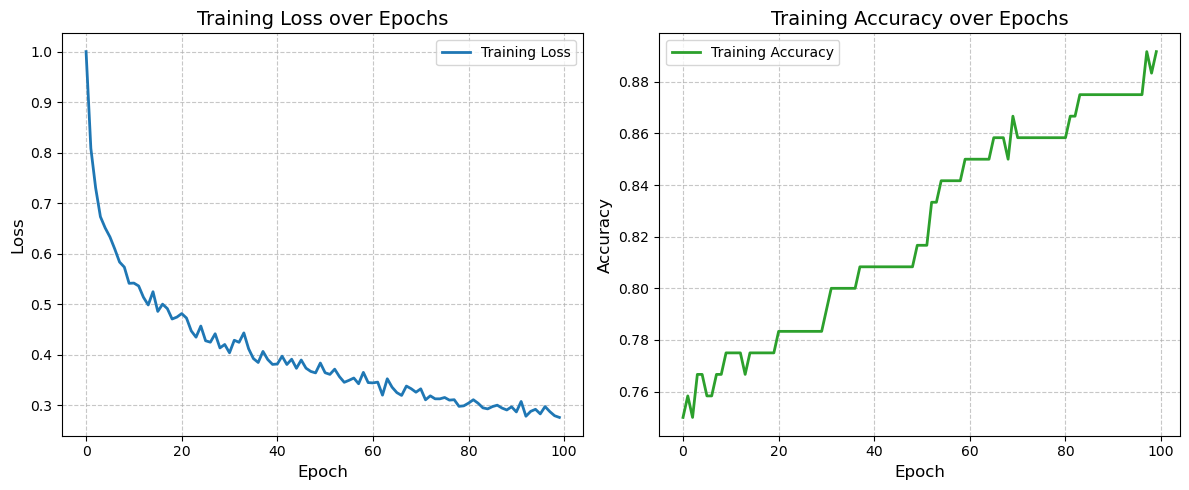

In [17]:
# ==========================================
# Model Training, Evaluation, and Visualization
# ==========================================

# 1. Initialize the model
# Assignment requirement: hidden layer = 16, learning rate = 0.01
print("Initializing SimpleMLP...")
mlp = SimpleMLP(input_size=4, hidden_size=16, output_size=3, learning_rate=0.01)

# 2. Train the model
# Assignment requirement: 100 epochs, batch size = 16
print("\nStarting training process...")
history = mlp.train(X_train, y_train_encoded, epochs=100, batch_size=16)
print("Training finished!")

# 3. Evaluate on the Test Set (Crucial for the assignment)
# We use X_test and compare the predictions with the original integer labels (y_test)
test_predictions = mlp.predict(X_test)
test_accuracy = np.mean(test_predictions == y_test)

print(f"\n=========================================")
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"=========================================\n")

# 4. Plot Learning Curves (Essential for HD Report)
# Plotting the loss and accuracy over epochs demonstrates a deep understanding of model convergence.
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Plot Cross-Entropy Loss
plt.subplot(1, 2, 1)
plt.plot(history['loss'], label='Training Loss', color='#1f77b4', linewidth=2)
plt.title('Training Loss over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Plot Training Accuracy
plt.subplot(1, 2, 2)
plt.plot(history['accuracy'], label='Training Accuracy', color='#2ca02c', linewidth=2)
plt.title('Training Accuracy over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()